# Lab 3: LSTM Forecasting of Monthly Precipitation (Honolulu Airport, Hawaii, 1940 to 2024)

Forecasts next month precipitation from the previous 12 months with a stacked LSTM in
PyTorch, using a chronological train/test split so the model never sees the future.

**Data:** NOAA National Centers for Environmental Information monthly precipitation for
Honolulu Airport, June 1940 to February 2024 (1,005 months). The file has four header lines,
then `Date` (YYYYMM), `Value` (inches) and `Anomaly`; `-99` marks a missing month.

**Run in Google Colab.** Upload `HW_precipitation_1939_2024.csv` and run all cells.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DATA_PATH = "HW_precipitation_1939_2024.csv"
WINDOW = 12

1005 months, 8 missing months filled by interpolation


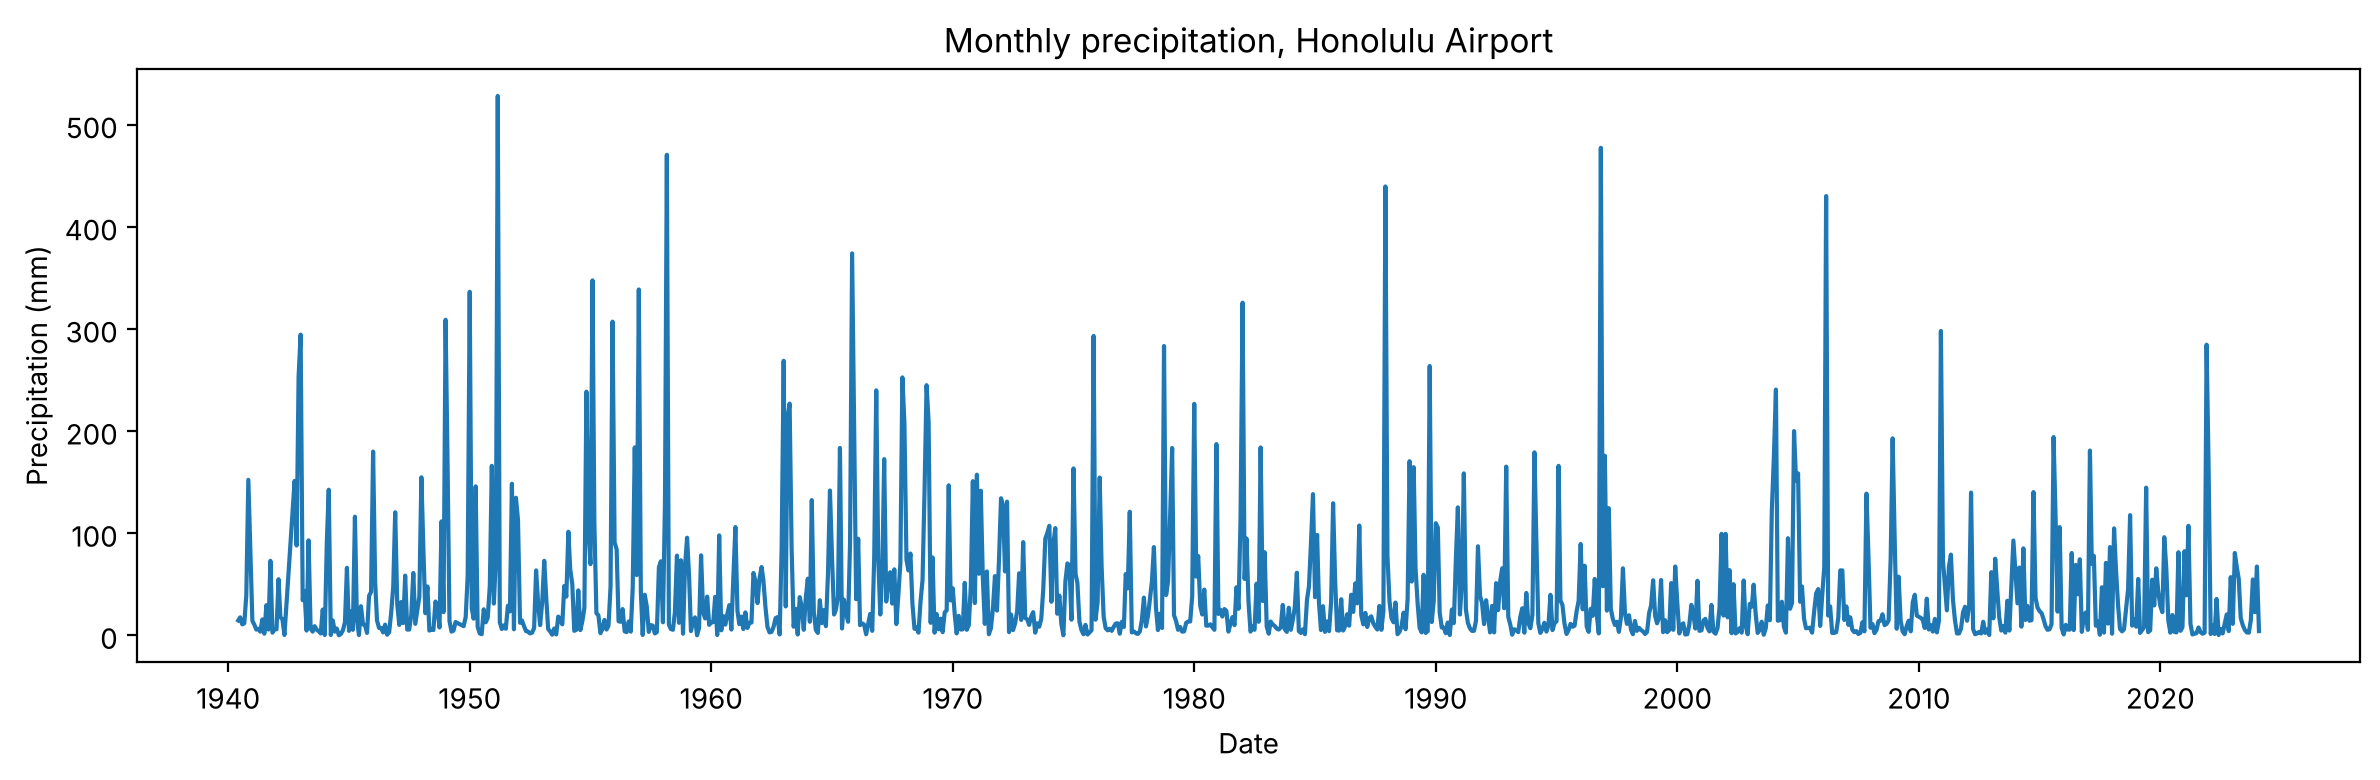

In [2]:
data = pd.read_csv(DATA_PATH, skiprows=4)        # first four lines are NOAA header text
data["Date"] = pd.to_datetime(data["Date"].astype(str), format="%Y%m")
data = data.sort_values("Date").reset_index(drop=True)

# -99 marks a missing month; convert inches to mm, then fill the few gaps by linear interpolation
data["Precipitation"] = data["Value"].replace(-99, np.nan) * 25.4
print(f"{len(data)} months, {data['Precipitation'].isna().sum()} missing months filled by interpolation")
data["Precipitation"] = data["Precipitation"].interpolate()

plt.figure(figsize=(12, 4))
plt.plot(data["Date"], data["Precipitation"])
plt.title("Monthly precipitation, Honolulu Airport"); plt.xlabel("Date"); plt.ylabel("Precipitation (mm)")
plt.tight_layout(); plt.show()

## Build sequences
Each input is 12 months (P1 to P12) and each target is the same window shifted one month
(P2 to P13), as the lab specifies. The last value of each target is the next month forecast.

In [3]:
values = data["Precipitation"].values.astype("float32").reshape(-1, 1)

split = int(len(values) * 0.8)                 # chronological split
scaler = MinMaxScaler().fit(values[:split])    # fit on the training period only
scaled = scaler.transform(values).astype("float32")

def make_sequences(series, window):
    X, Y = [], []
    for i in range(len(series) - window):
        X.append(series[i:i + window])            # P1 ... P12
        Y.append(series[i + 1:i + window + 1])    # P2 ... P13
    return np.array(X), np.array(Y)

X, Y = make_sequences(scaled, WINDOW)          # X, Y: (n, 12, 1)
n_train = split - WINDOW                       # every training target ends inside the training period
X_train, Y_train = X[:n_train], Y[:n_train]
X_test, Y_test = X[n_train:], Y[n_train:]
test_dates = data["Date"].values[split:]
print(X_train.shape, Y_train.shape, X_test.shape, Y_test.shape)

# Hold out the last 10 years of the training period as a validation set for choosing the
# epoch, so the test period is never used for any decision
VAL_MONTHS = 120
n_fit = n_train - VAL_MONTHS
X_fit_t, Y_fit_t = torch.tensor(X_train[:n_fit]), torch.tensor(Y_train[:n_fit])
X_val_t, Y_val_t = torch.tensor(X_train[n_fit:]), torch.tensor(Y_train[n_fit:])
X_test_t, Y_test_t = torch.tensor(X_test), torch.tensor(Y_test)
train_loader = DataLoader(TensorDataset(X_fit_t, Y_fit_t), batch_size=64, shuffle=True)
print(f"Train sequences {n_fit}, validation {VAL_MONTHS}, test {len(X_test)}")

(792, 12, 1) (792, 12, 1) (201, 12, 1) (201, 12, 1)
Train sequences 672, validation 120, test 201


## TimeSeriesNN: 3 layer LSTM (hidden size 40) and one linear layer

In [4]:
class TimeSeriesNN(nn.Module):
    def __init__(self, hidden=40, layers=3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, num_layers=layers, batch_first=True)
        self.linear = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)                  # (batch, 12, hidden)
        return self.linear(out)                # (batch, 12, 1): a forecast at every step

model = TimeSeriesNN()
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Train for 100 epochs, with train and test MAE every epoch
The weights from the epoch with the lowest validation MAE are kept for the final test.

In [5]:
MM = scaler.data_range_[0]                     # scaled error x data range = error in mm

def next_month_mae(X_t, Y_t):
    model.eval()
    with torch.no_grad():
        return (model(X_t)[:, -1] - Y_t[:, -1]).abs().mean().item() * MM

import copy
train_mae, val_mae, test_mae = [], [], []
best_val, best_epoch, best_state = float("inf"), 0, None
for epoch in range(100):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)        # MAE over all 12 shifted steps
        loss.backward()
        optimizer.step()
    train_mae.append(next_month_mae(X_fit_t, Y_fit_t))
    val_mae.append(next_month_mae(X_val_t, Y_val_t))
    test_mae.append(next_month_mae(X_test_t, Y_test_t))
    if val_mae[-1] < best_val:
        best_val, best_epoch, best_state = val_mae[-1], epoch + 1, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch + 1:3d}: train MAE {train_mae[-1]:5.1f} mm | validation {val_mae[-1]:5.1f} mm | test {test_mae[-1]:5.1f} mm")

model.load_state_dict(best_state)
print(f"Kept epoch {best_epoch} (lowest validation MAE, {best_val:.1f} mm)")

Epoch   1: train MAE  38.6 mm | validation  26.3 mm | test  28.4 mm


Epoch   2: train MAE  37.4 mm | validation  27.0 mm | test  29.0 mm


Epoch   3: train MAE  37.7 mm | validation  25.9 mm | test  28.1 mm


Epoch   4: train MAE  37.4 mm | validation  26.5 mm | test  28.7 mm


Epoch   5: train MAE  37.4 mm | validation  26.4 mm | test  28.6 mm


Epoch   6: train MAE  37.4 mm | validation  26.8 mm | test  28.9 mm


... (85 outputs left out)

Epoch  97: train MAE  32.9 mm | validation  28.3 mm | test  28.2 mm


Epoch  98: train MAE  33.1 mm | validation  29.1 mm | test  29.2 mm


Epoch  99: train MAE  33.0 mm | validation  27.6 mm | test  27.6 mm


Epoch 100: train MAE  32.8 mm | validation  28.6 mm | test  28.5 mm
Kept epoch 34 (lowest validation MAE, 25.2 mm)


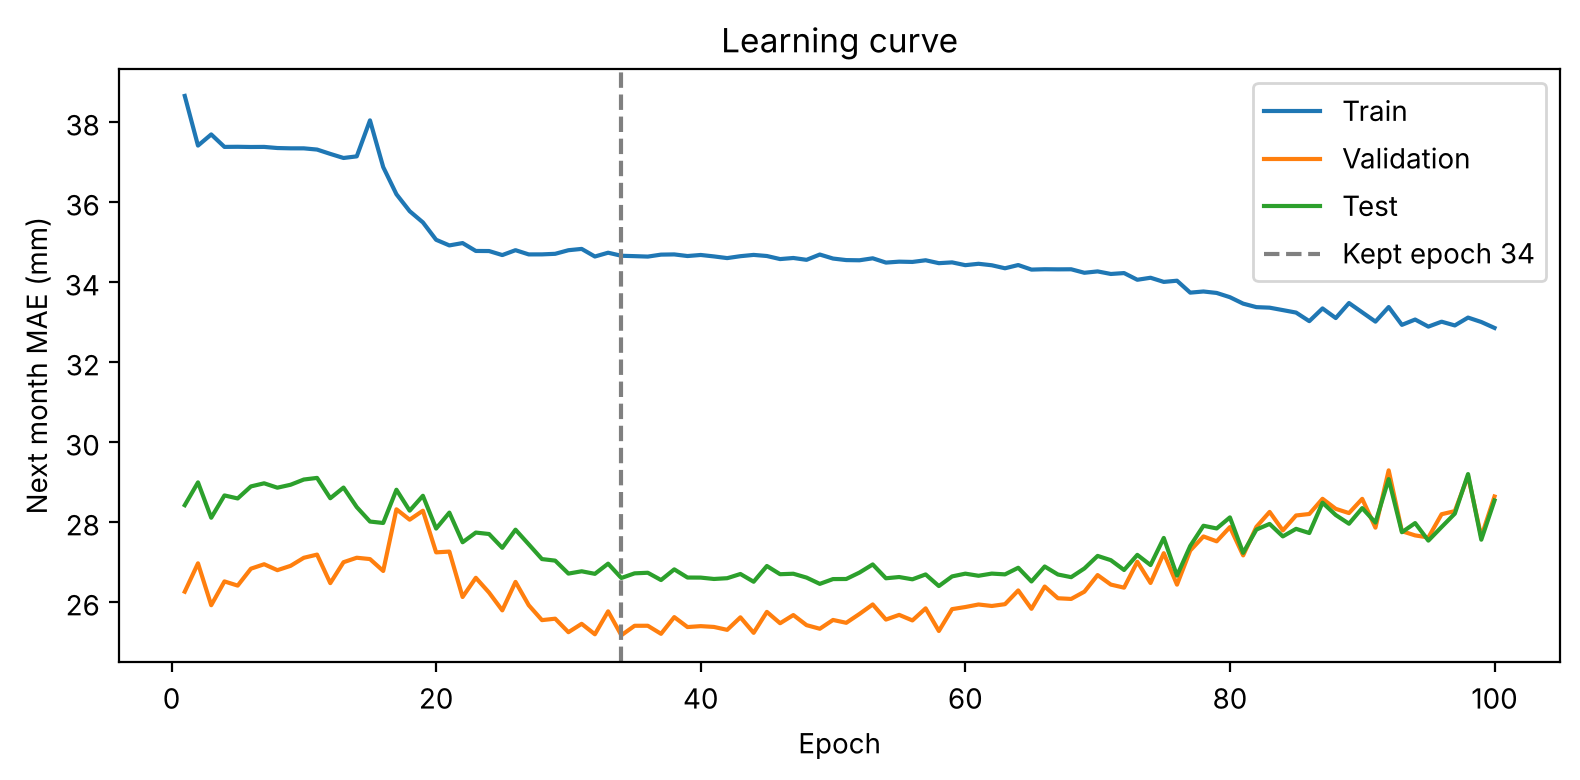

In [6]:
plt.figure(figsize=(8, 4))
epochs = range(1, 101)
plt.plot(epochs, train_mae, label="Train")
plt.plot(epochs, val_mae, label="Validation")
plt.plot(epochs, test_mae, label="Test")
plt.axvline(best_epoch, color="grey", linestyle="--", label=f"Kept epoch {best_epoch}")
plt.xlabel("Epoch"); plt.ylabel("Next month MAE (mm)")
plt.title("Learning curve")
plt.legend(); plt.tight_layout(); plt.show()

## Evaluate in millimetres

LSTM test MAE: 26.6 mm
Seasonal median baseline MAE: 27.5 mm
Naive (same as last month) baseline MAE: 37.5 mm


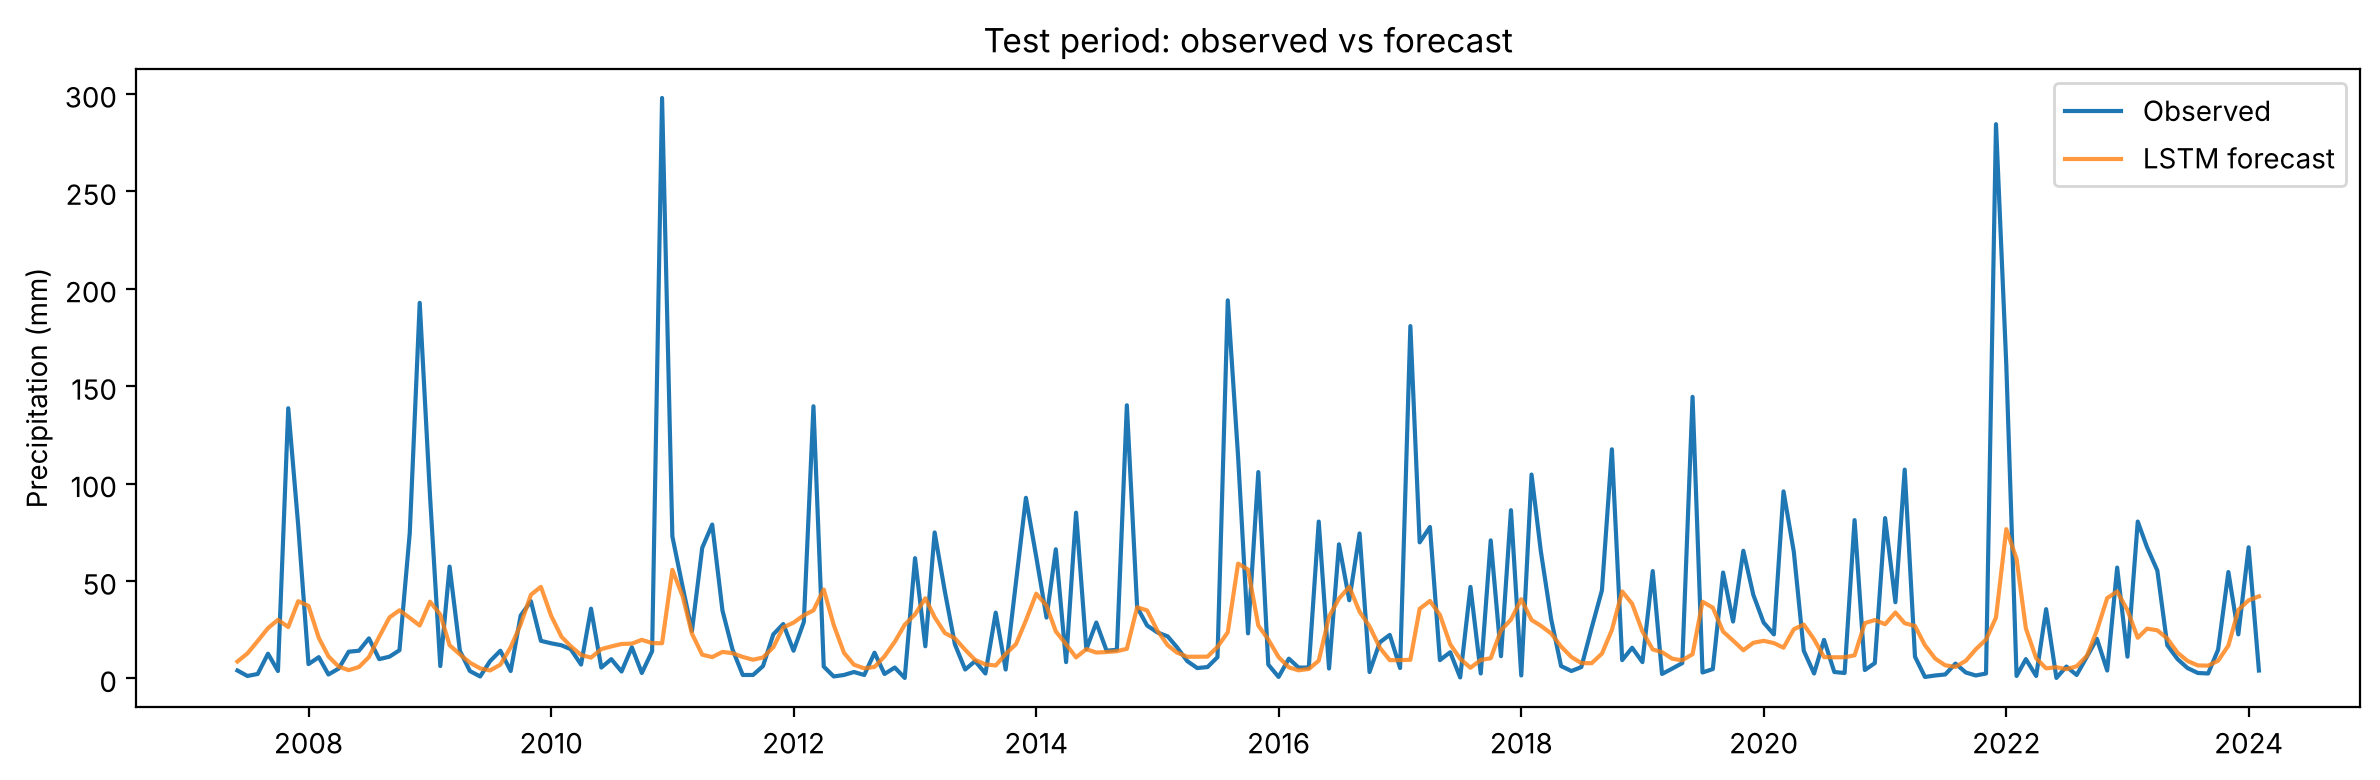

In [7]:
model.eval()
with torch.no_grad():
    preds_scaled = model(X_test_t)[:, -1].numpy()          # next month forecast
preds = scaler.inverse_transform(preds_scaled).ravel()
truth = scaler.inverse_transform(Y_test[:, -1]).ravel()
mae_mm = np.mean(np.abs(preds - truth))
naive_mae = np.mean(np.abs(truth[1:] - truth[:-1]))   # baseline: next month equals this month

# Seasonal baseline: the median for each calendar month, from the training years only
train_months = data["Date"].dt.month.values[:split]
monthly_median = pd.Series(values[:split].ravel()).groupby(train_months).median()
seasonal_pred = monthly_median.loc[data["Date"].dt.month.values[split:]].values
seasonal_mae = np.mean(np.abs(seasonal_pred - truth))

print(f"LSTM test MAE: {mae_mm:.1f} mm")
print(f"Seasonal median baseline MAE: {seasonal_mae:.1f} mm")
print(f"Naive (same as last month) baseline MAE: {naive_mae:.1f} mm")

plt.figure(figsize=(12, 4))
plt.plot(test_dates, truth, label="Observed")
plt.plot(test_dates, preds, label="LSTM forecast", alpha=0.8)
plt.title("Test period: observed vs forecast"); plt.ylabel("Precipitation (mm)")
plt.legend(); plt.tight_layout(); plt.show()